# Los modelos con retención y los controles: dónde el modelo calibrado tiene habilidad y dónde no

**Pregunta:** ¿Para cuál de los dos objetivos medidos el modelo calibrado con retención supera a la línea base de media constante, y aprende el modelo de residuo, que agrega parámetros libres encima, algo que un control de barajado de etiquetas no aprende?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook usted puede:

- ajustar pliegue por pliegue el modelo calibrado, el modelo de residuo acotado, la regresión libre y la media constante, para el tonelaje y para la potencia, con las funciones públicas de CrusherCal;
- aplicar la línea base de media constante y decir para qué objetivo el modelo calibrado la supera;
- leer el residuo acotado antes y después de su recorte, y leer el modelo de residuo como la hipótesis nula preregistrada que es;
- ejecutar el control de barajado de etiquetas con muchas semillas, y decir qué prueba: el modelo de residuo, no la habilidad del modelo calibrado.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el motor con su vía calibrada y su potencia de Bond, y el módulo CrusherCal.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import HP500_QREF, bond_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
from pipeline.hp500 import loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivo leído: `data/examples/hp500-surveys.csv`. Los dos objetivos medidos son el tonelaje en t/h y la potencia en kW; el tamaño de producto es una salida del modelo, así que aquí no es un objetivo.

La celda lee la tabla y deja los dos objetivos medidos y los dos regresores del modelo libre, la abertura y el f80.

In [2]:
# Lea la tabla de muestreos y deje los dos objetivos medidos y los regresores, la abertura y el f80
surveys = read_surveys().accepted
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
targets = {"tph": measured_q, "kW": measured_kw}
print("muestreos:", len(surveys), "| rango de tonelaje [t/h]:", measured_q.min(), measured_q.max())
print("rango de potencia [kW]:", measured_kw.min(), measured_kw.max())

muestreos: 10 | rango de tonelaje [t/h]: 813.0 1639.0
rango de potencia [kW]: 187.0 355.0


## Método

**Paso 1, las entradas de los dos modelos calibrados.** El modelo M0 de CrusherCal es la física del motor con sus escalares globales reajustados en cada pliegue. Para el tonelaje es $Q = Q_T\,s_i$, con $s_i$ el factor de capacidad del motor en el muestreo $i$ (su tonelaje sobre la base de 647 t/h del artículo) y $Q_T$ el único escalar reajustado. Para la potencia es la forma del artículo $P_c = \zeta\,P_d + P_n$ (Rocha et al., 2024; https://doi.org/10.3390/min14090919), con $P_d$ la potencia de Bond del motor y los dos coeficientes reajustados. La celda ejecuta el motor en los diez muestreos e imprime las dos entradas.

In [3]:
# Las entradas de los dos modelos base, a 0,01 como las llevan los documentos versionados: capacidad y potencia de Bond
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
shape = np.array([r.throughput_tph for r in runs]).round(2) / HP500_QREF
bond_kw = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs]).round(2)
print("factor de capacidad por muestreo:", shape.round(3))
print("potencia de Bond por muestreo [kW]:", bond_kw.round(1))

factor de capacidad por muestreo: [1.868 1.868 1.711 1.711 1.711 1.5   1.447 1.605 1.5   1.895]
potencia de Bond por muestreo [kW]: [229.5 233.7 224.9 225.7 234.8 222.5 196.1 212.7 221.6 237.5]


**Paso 2, los pliegues estrictos.** En cada uno de los diez pliegues la celda reajusta los escalares de M0 con nueve muestreos (`fit_capacity_base`, `fit_power_form`), reajusta la regresión libre M2 sobre la abertura y el f80 (`fit_freeform`), y toma la media de los nueve como línea base. M2 no tiene física y tiene tres coeficientes por objetivo, el hombre de paja del sobreajuste que el protocolo espera que pierda. La celda imprime cómo se mueven los escalares reajustados de un pliegue a otro.

In [4]:
# Los diez pliegues estrictos y, en cada uno, el modelo calibrado M0, la regresión libre M2 y la media constante
folds = [loo.fold_indices(10, i, leaky=False) for i in range(10)]
qt = [loo.fit_capacity_base(shape, measured_q, rows) for rows in folds]
power_form = [loo.fit_power_form(bond_kw, measured_kw, rows) for rows in folds]
pred = {("tph", "M0"): np.array([loo.predict_capacity(q, shape, i) for i, q in enumerate(qt)]),
        ("kW", "M0"): np.array([z * bond_kw[i] + pn for i, (z, pn) in enumerate(power_form)])}
for key, y in targets.items():
    free = [loo.fit_freeform(features, y, rows) for rows in folds]
    pred[key, "M2"] = np.array([loo.predict_freeform(c, features[i]) for i, c in enumerate(free)])
    pred[key, "mean"] = np.array([y[rows].mean() for rows in folds])
print("base de capacidad por pliegue [t/h]:", np.round(qt, 1))
print("forma de potencia, zeta por pliegue:", np.round([z for z, _ in power_form], 2))
print("forma de potencia, Pn por pliegue [kW]:", np.round([pn for _, pn in power_form], 1))

base de capacidad por pliegue [t/h]: [659.3 687.1 681.5 695.3 689.3 698.3 682.9 683.7 697.9 683.4]
forma de potencia, zeta por pliegue: [-2.1  -1.95 -2.4  -2.51 -3.05 -2.34 -5.56 -2.31 -2.31 -1.5 ]
forma de potencia, Pn por pliegue [kW]: [ 766.   731.   827.   842.8  962.5  805.  1547.   804.1  797.8  633.8]


La base de capacidad se mueve entre 659 y 698 t/h de un pliegue a otro, como en el notebook 01, y el modelo de tonelaje sigue siendo un ajuste de un parámetro. La forma de potencia no se comporta como debería un coeficiente físico. En los diez pliegues $\zeta$ sale negativo, de -5,56 a -1,5, cuando el valor del propio artículo es +1,30, y $P_n$ oscila de 634 a 1547 kW para compensar. La potencia medida baja al abrir la abertura mientras la potencia de Bond del motor sube con ella (la tabla del notebook 02 del tema 05), así que una recta de mínimos cuadrados sobre la potencia de Bond toma pendiente negativa, y el pliegue sin el muestreo 7 (abertura de 38 mm, la menor potencia de Bond, 196 kW, con 306 kW medidos) es el extremo, en -5,56. Un coeficiente con el signo contrario de la física que representa significa que la forma predice a través de su intercepto, y eso es lo que hay que recordar al leer los puntajes de potencia.

**Paso 3, el residuo acotado.** El modelo de residuo M1 es la propuesta preregistrada de CrusherCal: una regresión ridge (penalización 1) del residuo de M0 sobre la abertura y el f80 estandarizados, ajustada con los nueve muestreos de entrenamiento y sumada a M0, con su valor recortado a más o menos 20 por ciento de M0 para que siga siendo una corrección física y no un segundo modelo. La celda sigue un pliegue, el muestreo 1 en el tonelaje, a través de `fit_residual`: los coeficientes, el residuo bruto que predice, la cota del recorte y el valor recortado que se suma.

In [5]:
# M1 en un pliegue, el muestreo 1 en el tonelaje: el residuo ridge antes y después del recorte de 20 %
fit = loo.fit_residual(features, pred["tph", "M0"], measured_q, folds[0], 0)
m0_first = pred["tph", "M0"][0]
bound = loo.RESID_CLIP_FRAC * abs(m0_first)
print("coeficientes ridge (intercepto, abertura, f80), variables estandarizadas:", np.round(fit.coef, 1))
print(f"residuo bruto {fit.raw:+.1f} t/h | cota +-{bound:.1f} t/h | residuo recortado {fit.clipped:+.1f} t/h")
print(f"M0 {m0_first:.1f} + recortado = M1 {m0_first + fit.clipped:.1f} t/h | medido {measured_q[0]:.0f} t/h")

coeficientes ridge (intercepto, abertura, f80), variables estandarizadas: [-52.6  56.4  45.5]
residuo bruto +26.3 t/h | cota +-246.4 t/h | residuo recortado +26.3 t/h
M0 1231.9 + recortado = M1 1258.2 t/h | medido 1639 t/h


Para el muestreo 1 el residuo ridge predice +26,3 t/h, muy dentro de la cota de +-246,4 t/h, así que el recorte no hace nada aquí, y M1 mueve la predicción de 1231,9 a 1258,2 t/h cuando la medición es 1639: de los 407 t/h que M0 no alcanza, el modelo de residuo, entrenado con los otros nueve muestreos, recupera 26. Eso es lo que puede hacer un residuo aprendido de nueve puntos en el muestreo que menos se parece a ellos. Los coeficientes están en unidades estandarizadas, así que su tamaño (56,4 para la abertura, 45,5 para el f80) es el ajuste ridge frente a un intercepto cercano a -53, no una pendiente física. La celda siguiente repite el pliegue para cada muestreo e imprime en cuántos pliegues actúa el recorte.

La celda repite el pliegue para cada muestreo y ambos objetivos y guarda los residuos recortados y las predicciones de M1.

In [6]:
# M1 en cada pliegue y para ambos objetivos: el modelo calibrado más el residuo ridge recortado
for key, y in targets.items():
    base = pred[key, "M0"]
    fits = [loo.fit_residual(features, base, y, rows, i) for i, rows in enumerate(folds)]
    clipped = np.array([f.clipped for f in fits])
    pred[key, "M1"] = base + clipped
    acting = sum(abs(f.raw) > loo.RESID_CLIP_FRAC * abs(base[i]) for i, f in enumerate(fits))
    print(key, "residuo recortado por pliegue:", np.round(clipped, 1), "| pliegues donde actúa el recorte:", acting)

tph residuo recortado por pliegue: [  26.3  154.4 -173.7   34.2  -47.1 -117.9 -155.4   25.7 -115.9  157.6] | pliegues donde actúa el recorte: 0
kW residuo recortado por pliegue: [-45.3 -40.6  57.7 -28.7  13.6  31.8  72.9 -62.5  30.7 -30.5] | pliegues donde actúa el recorte: 2


**Paso 4, los puntajes con retención y la línea base.** La habilidad es el error con retención relativo al de la línea base: un modelo debe estar bajo la media constante para reclamarla. La celda puntúa los cuatro modelos en ambos objetivos con `loo.mape` e imprime la reducción relativa de M0 frente a la media. Una reducción negativa significa que el modelo es peor que adivinar la media. La figura dibuja los cuatro puntajes por objetivo.

In [7]:
# MAPE con retención de los cuatro modelos para ambos objetivos, y reducción de M0 frente a la media constante
models = ("M0", "M1", "M2", "mean")
labels = {"M0": "M0", "M1": "M1", "M2": "M2", "mean": "media"}
score = {(key, m): loo.mape(y, pred[key, m]) for key, y in targets.items() for m in models}
for key in targets:
    print(key, {labels[m]: round(score[key, m], 2) for m in models})
    gain = (score[key, "mean"] - score[key, "M0"]) / score[key, "mean"] * 100
    print(f"     reducción de M0 frente a la media: {gain:+.1f} %")

tph {'M0': 12.09, 'M1': 13.45, 'M2': 12.18, 'media': 18.29}
     reducción de M0 frente a la media: +33.9 %
kW {'M0': 25.94, 'M1': 25.37, 'M2': 14.03, 'media': 24.48}
     reducción de M0 frente a la media: -6.0 %


La figura dibuja el MAPE con retención de los cuatro modelos, un grupo por objetivo. El modelo llamado media es la línea base de media constante.

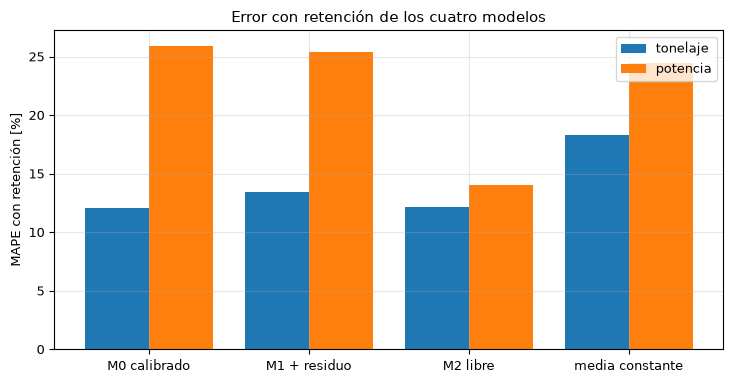

In [8]:
# Gráfico de barras del MAPE con retención de los cuatro modelos para el tonelaje y para la potencia
fig, ax = plt.subplots()
x = np.arange(len(models))
ax.bar(x - 0.2, [score["tph", m] for m in models], 0.4, label="tonelaje")
ax.bar(x + 0.2, [score["kW", m] for m in models], 0.4, label="potencia")
ax.set_xticks(x, ["M0 calibrado", "M1 + residuo", "M2 libre", "media constante"])
ax.set_ylabel("MAPE con retención [%]")
ax.set_title("Error con retención de los cuatro modelos")
ax.legend()
fig.tight_layout()
plt.show()

Para el tonelaje el modelo calibrado M0 puntúa 12,09 por ciento frente a 18,29 por ciento de la media constante, una reducción de 33,9 por ciento, y el modelo de residuo acotado M1 es peor que M0, 13,45 por ciento, así que el residuo no aporta nada fuera de la muestra; la regresión libre M2, con tres coeficientes y sin física, está en 12,18 por ciento, tan buena como la física con una diferencia de 0,1 puntos. Para la potencia el modelo calibrado está en 25,94 por ciento frente a 24,48 por ciento de la media, 6,0 por ciento peor que adivinar la media, y M1 con 25,37 por ciento no es mejor en lo sustancial. La regresión libre es la mejor de las cuatro en potencia, 14,03 por ciento, porque la potencia medida sigue a la abertura y una regresión sobre la abertura la sigue, mientras la forma impulsada por Bond no puede. El recorte no actúa en ninguno de los diez pliegues de tonelaje y actúa en dos de los diez de potencia (impreso arriba). La figura muestra el orden; las barras de la potencia muestran un modelo con física que pierde frente a una constante, y uno sin física que gana.

**Paso 5, el control con muchas semillas.** El control de barajado de etiquetas ajusta el modelo de residuo a mediciones permutadas: el residuo que M1 aprende de las etiquetas verdaderas se reemplaza por uno aprendido de etiquetas sin relación con los muestreos, y el resultado se suma a M0 y se recorta igual. El control prueba por tanto el modelo de residuo, no el modelo calibrado: pregunta con qué frecuencia un residuo que no sabe nada mejora a M0 por azar, y así cuánto debería mejorarlo un residuo real para ser creído. Con diez puntos un solo sorteo dice poco, así que la celda repite el control con 200 semillas (el documento versionado del pipeline guarda uno solo, la semilla 42) y registra cada vez el error con retención del modelo barajado. Cada objetivo saca su permutación de su propio flujo, como hace CrusherCal (la semilla para el tonelaje, la semilla más 1 para la potencia).

In [9]:
# El control de barajado: M0 más un residuo ridge ajustado a etiquetas permutadas, 200 semillas y la semilla 42
seeds = [42] + list(range(1, 201))
control = {"tph": [], "kW": []}
for seed in seeds:
    for offset, key in enumerate(targets):
        y, base = targets[key], pred[key, "M0"]
        permuted = y.copy()
        np.random.default_rng(seed + offset).shuffle(permuted)
        fits = [loo.fit_residual(features, base, permuted, rows, i, resid_target=permuted - base).clipped
                for i, rows in enumerate(folds)]
        control[key].append(loo.mape(y, base + np.array(fits)))
for key in targets:
    print(f"{key:4s} semilla versionada 42: {control[key][0]:6.2f} %")

tph  semilla versionada 42:  25.04 %
kW   semilla versionada 42:  40.19 %


La celda resume las 200 semillas: la distribución del error del modelo barajado y las semillas en que supera a M0 y a M1.

In [10]:
# Distribución del control de barajado sobre las 200 semillas, y las semillas en que supera a M0 y a M1
for key in targets:
    values = np.array(control[key][1:])
    beats_m0, beats_m1 = int((values < score[key, "M0"]).sum()), int((values < score[key, "M1"]).sum())
    print(f"{key:4s} control de barajado: media {values.mean():6.2f} %", end=", ")
    print(f"mín {values.min():6.2f} %, máx {values.max():6.2f} %")
    print(f"     semillas que superan a M0: {beats_m0} de 200 | semillas que superan a M1: {beats_m1} de 200")

tph  control de barajado: media  18.36 %, mín  10.45 %, máx  25.76 %
     semillas que superan a M0: 5 de 200 | semillas que superan a M1: 17 de 200
kW   control de barajado: media  32.19 %, mín  19.08 %, máx  42.00 %
     semillas que superan a M0: 21 de 200 | semillas que superan a M1: 16 de 200


La figura muestra los 200 errores barajados como histograma para cada objetivo, con el error con retención de M0 y de M1 como líneas verticales.

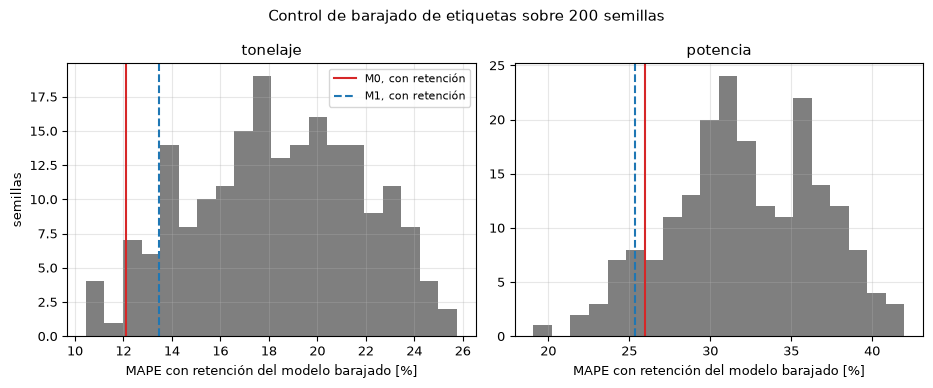

In [11]:
# Histograma del error del control de barajado sobre 200 semillas, por objetivo, frente a M0 y M1 con retención
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in ((left, "tph", "tonelaje"), (right, "kW", "potencia")):
    ax.hist(control[key][1:], bins=20, color="tab:grey")
    ax.axvline(score[key, "M0"], color="tab:red", lw=1.5, label="M0, con retención")
    ax.axvline(score[key, "M1"], color="tab:blue", lw=1.5, ls="--", label="M1, con retención")
    ax.set_xlabel("MAPE con retención del modelo barajado [%]")
    ax.set_title(label)
left.set_ylabel("semillas")
left.legend(fontsize=8)
fig.suptitle("Control de barajado de etiquetas sobre 200 semillas")
fig.tight_layout()
plt.show()

Para el tonelaje, M0 está en el extremo izquierdo del histograma: solo 5 de los 200 modelos barajados son más exactos que él, de modo que un residuo que no sabe nada casi nunca mejora al modelo calibrado por azar. M1 es otra cosa. Con 13,45 por ciento lo superan 17 de los 200 modelos barajados, así que el residuo aprendido de las etiquetas verdaderas es difícil de distinguir de uno aprendido del ruido, y el modelo de residuo no tiene habilidad demostrada; esa es la hipótesis nula preregistrada, informada como tal. Para la potencia, el modelo de residuo vuelve a ser nulo: 16 de los 200 modelos barajados superan a M1, casi lo mismo que los 17 del tonelaje. Los 21 que superan a M0 en la potencia solo cuentan cuántas veces un residuo de ruido mejora a M0, lo que no es evidencia sobre la habilidad del propio M0. Esa descansa en la línea base del paso 4, donde el modelo de tonelaje supera a la media en 33,9 por ciento y el de potencia, con 25,94 frente a 24,48 por ciento, no. Los dos histogramas son la razón de ejecutar el control con muchas semillas: un solo sorteo con la semilla versionada 42, 25,04 y 40,19 por ciento, habría mostrado al modelo barajado peor que M0 en ambos objetivos, y la distribución muestra que el modelo de residuo M1 es nulo en ambos objetivos, con 17 y 16 de 200 modelos barajados que lo superan.

## Resultados

**Respuesta:** el modelo calibrado con retención supera a la línea base de media constante en el tonelaje, 12,09 frente a 18,29 por ciento, una reducción de 33,9 por ciento, y no la supera en la potencia, 25,94 frente a 24,48 por ciento, 6,0 por ciento peor que adivinar la media. El modelo de residuo acotado M1 no mejora el tonelaje, 13,45 frente a 12,09 por ciento, y mueve la potencia solo de 25,94 a 25,37. El control de barajado de etiquetas con 200 semillas, un residuo ajustado a etiquetas permutadas, supera a M0 en 5 semillas para el tonelaje y en 21 para la potencia, y supera a M1 en 17 y 16: el modelo de residuo no se distingue del ruido, mientras la habilidad de tonelaje de M0 descansa en la línea base y la de potencia no existe.

La primera figura muestra el error con retención de los cuatro modelos en ambos objetivos y la segunda la distribución del control frente a M0 y M1. Un validador concluiría que la afirmación de tonelaje del producto se sostiene y la de potencia no, que es lo que el producto informa; que una semilla de un control no es un control; y que el control prueba el modelo de residuo y no el modelo base. El error de potencia con retención de la regresión libre, 14,03 por ciento, es menor que el de cualquier modelo con física, un hallazgo para el que el producto no reclama uso: la potencia medida sigue a la abertura, lo que una regresión sobre la abertura captura y un consumo de Bond no.

## Resumen

La comparación con retención separa los dos objetivos: el modelo de tonelaje tiene una habilidad que supera a una línea base, el de potencia no tiene ninguna, y la regresión libre lo hace mejor en la potencia porque lee la abertura. El modelo de residuo es una hipótesis nula, y el control de barajado, ejecutado con 200 semillas, es lo que lo muestra; el control prueba el residuo, así que las afirmaciones de habilidad descansan en la línea base. Los números descansan en diez muestreos, y la dispersión del propio control muestra cuán gruesos son. El notebook 03 pone el protocolo dentro de la muestra del artículo junto a este, y el notebook 04 enuncia y mide la afirmación del producto más allá de él.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919